In [109]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Фіксація seed за номером варіанта (1) для Києва
np.random.seed(1)
city = "Київ"
base_temp = 9.5
amplitude = 14
base_consumption = 5200
k = 50
noise_sd = 80

months = np.arange(1, 13)
temp = base_temp + amplitude * np.cos((months - 7) / 12 * 2 * np.pi)
temp = np.round(temp + np.random.normal(0, 0.5, size=12), 1)

# Генерація споживання електроенергії
consumption = base_consumption - k * (temp - base_temp) + np.random.normal(0, noise_sd, size=12)
consumption = np.round(consumption, 0)

city_data = pd.DataFrame({
    "місяць": months,
    "температура": temp,
    "споживання_МВтгод": consumption,
})

print("Згенеровані дані споживання для м. Київ:")
display(city_data)

Згенеровані дані споживання для м. Київ:


,місяць,температура,споживання_МВтгод
0,1,-3.7,5834.0
1,2,-2.9,5789.0
2,3,2.2,5656.0
3,4,9.0,5137.0
4,5,16.9,4816.0
5,6,20.5,4580.0
6,7,24.4,4458.0
7,8,21.2,4662.0
8,9,16.7,4752.0
9,10,9.4,5297.0


In [110]:
# Завдання 2. Підбір коефіцієнтів лінійної моделі
b, a = np.polyfit(city_data["температура"], city_data["споживання_МВтгод"], 1)

print(f"Побудована модель: споживання ≈ {a:.1f} + ({b:.1f}) · температура")

city_data["передбачення"] = a + b * city_data["температура"]
display(city_data)

Побудована модель: споживання ≈ 5691.7 + (-51.5) · температура


,місяць,температура,споживання_МВтгод,передбачення
0,1,-3.7,5834.0,5882.270496
1,2,-2.9,5789.0,5841.056050
2,3,2.2,5656.0,5578.313953
3,4,9.0,5137.0,5227.991159
4,5,16.9,4816.0,4820.998500
5,6,20.5,4580.0,4635.533491
6,7,24.4,4458.0,4434.613064
7,8,21.2,4662.0,4599.470850
8,9,16.7,4752.0,4831.302111
9,10,9.4,5297.0,5207.383935


,місяць,температура,споживання_МВтгод,передбачення,залишок
0,1,-3.7,5834.0,5882.270496,-48.270496
1,2,-2.9,5789.0,5841.056050,-52.056050
2,3,2.2,5656.0,5578.313953,77.686047
3,4,9.0,5137.0,5227.991159,-90.991159
4,5,16.9,4816.0,4820.998500,-4.998500
5,6,20.5,4580.0,4635.533491,-55.533491
6,7,24.4,4458.0,4434.613064,23.386936
7,8,21.2,4662.0,4599.470850,62.529150
8,9,16.7,4752.0,4831.302111,-79.302111
9,10,9.4,5297.0,5207.383935,89.616065


Коефіцієнт детермінації R² = 0.9858


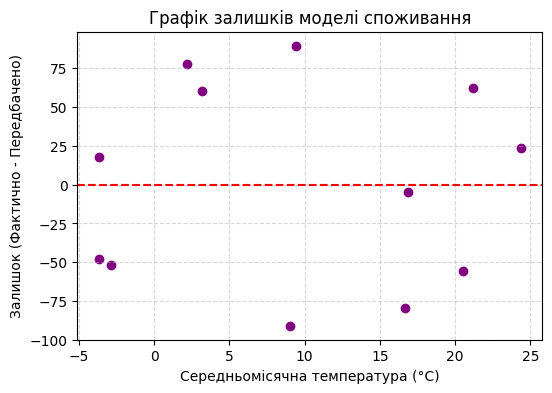

In [111]:
# Завдання 3. Розрахунок залишків та R²
city_data["залишок"] = city_data["споживання_МВтгод"] - city_data["передбачення"]
display(city_data[["місяць", "температура", "споживання_МВтгод", "передбачення", "залишок"]])

ss_res = (city_data["залишок"] ** 2).sum()
ss_tot = ((city_data["споживання_МВтгод"] - city_data["споживання_МВтгод"].mean()) ** 2).sum()
r_squared = 1 - ss_res / ss_tot

print(f"Коефіцієнт детермінації R² = {r_squared:.4f}")

# Графік залишків проти температури
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(city_data["температура"], city_data["залишок"], color="purple")
ax.axhline(0, color="red", linestyle="--")
ax.set_xlabel("Середньомісячна температура (°C)")
ax.set_ylabel("Залишок (Фактично - Передбачено)")
ax.set_title("Графік залишків моделі споживання")
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()

### Відповіді на контрольні запитання:

1. **Розмежування верифікації й валідації на прикладі:**
   - Верифікація перевіряє правильність побудови самої програми та формул (чи відповідає код математичній постановці регресії). Валідація перевіряє відповідність моделі зовнішній реальності — чи здатна вона точно прогнозувати нові дані поза межами навчальної вибірки.

2. **Класифікаційні ознаки моделі та їх узгодженість:**
   - Модель є стохастичною, статичною та описово-прогнозною. Ці ознаки не суперечать, а доповнюють одна одну, відповідаючи на різні питання: наявність випадкового шуму (стохастичність), відсутність часових лагів (статичність) та ціль застосування (прогноз за статистичними даними).

3. **Обмеження коефіцієнта $R^2$ та екстраполяція:**
   - Високий $R^2$ показує лише якість пояснення даних у межах спостереженого діапазону температур. Він автоматично не гарантує «правильності» моделі та її приступності для екстраполяції в зону екстремальних температур, де лінійний зв'язок може порушуватися.

4. **Чому структура залишків важливіша за сумарну величину:**
   - Сумарне відхилення може бути малим через взаємну компенсацію знаків (плюси гасять мінуси). Структура залишків (наявність трендів чи патернів) одразу сигналізує про концептуальні помилки у виборі форми моделі, які неможливо помітити за одним узагальненим числом.